## Tool (工具调用)

```
LangChain Tool（新版 1.0）
├── 定义工具：@tool 装饰器（最推荐）
│     ├── name（函数名）
│     ├── description（docstring）
│     └── args_schema（类型注解 → Pydantic）
├── 组装 Agent：create_agent(model, tools=[...], system_prompt, middleware)
├── 运行：agent.invoke({"messages": [...]})
├── 核心机制：模型输出 tool_call → 框架执行函数 → 结果回传（ReAct 循环）
└── 1.0 新变化：统一 create_agent、弃用 ToolNode、Middleware 中间件、wrap_tool_call 错误处理
```

### 1. 自定义工具案例

In [5]:
# 1. 必须知道各种工具的使用说明
# 2. 当遇到具体场景，能够从工具库中选择合适工具使用
# ============ Step 1：导入 ============
from langchain.agents import create_agent            # 新版统一入口
from langchain_core.tools import tool                # @tool 装饰器
from langchain.chat_models import init_chat_model    # ChatModel

# ============ Step 2：定义工具 ============
# 注意：函数的描述必须写在函数体中的第一行
@tool
def get_weather(city: str) -> str:
    """查询指定城市的实时天气。
    参数 city: 城市英文名，例如 Beijing、Shanghai。
    """
    # 真实场景这里应该调天气 API，这里用假数据演示
    return f"{city} 今天晴，25°C"

import datetime
@tool
def get_date():
    """ 获取今天的具体日期 """
    return datetime.date.today().strftime("%Y-%m-%d")

import webbrowser
@tool
def open_browser(url: str) -> str:
    """打开浏览器访问指定网址"""
    try:
        webbrowser.open(url)
        return f"已打开浏览器访问 {url}"
    except Exception as e:
        return f"打开浏览器失败: {str(e)}"


# ============ Step 3：创建模型 ============
model = init_chat_model(model="deepseek-flash")

# ============ Step 4：创建 Agent（把工具交给模型）============
from langgraph.checkpoint.memory import InMemorySaver
memory = InMemorySaver() # 创建短期记忆实例：智能体中使用InMemorySaver()实现单会话的短期记忆
agent = create_agent(
    model=model,
    tools=[get_weather, get_date, open_browser],          # 关键：这里传工具列表
    system_prompt= "你是人工智能助手。需要帮助用户解决各种问题。", # 【可选】系统提示词
    checkpointer=memory, # 【可选】记忆对象
)

# ============ Step 5：运行 ============
result = agent.invoke(
    {"messages": [{"role": "user", "content": "北京今天天气怎么样？"}]},
    config={"configurable": {"thread_id": "user_1"}}  # 会话唯一标识，用于区分不同用户
)
# result = agent.invoke({"messages":[{"role":"user","content":"今天是几月几号？"}]})
# result = agent.invoke({"messages":[{"role":"user","content":"帮我打开淘宝"}]})

# ============ Step 6：取最终回答 ============
print(result["messages"][-1].content)

北京今天的天气情况如下：

- **日期**：2026年10月10日
- **天气**：晴 ☀️
- **气温**：25°C

今天北京天气晴朗，气温舒适宜人，非常适合外出活动。不过秋季昼夜温差较大，建议您早晚适当增添衣物，注意保暖。☺️


In [2]:
print(type(result))
print(type(result['messages']))

<class 'dict'>
<class 'list'>


#### 前端交互
```
uv add gradio==5.49.1
```

In [2]:
# 与前端交互处理LLM响应
def process_llm_response(query, history):
    # type="messages" 模式下，history 是 [{"role":..., "content":...}, ...] 格式的列表
    history = history or []
    if len(query) == 0:
        return history
    user_msg = {"role": "user", "content": query}
    try:
        # 先展示用户消息 + "正在查询"占位
        yield history + [user_msg, {"role": "assistant", "content": "正在查询大模型..."}], ""

        # 使用Agent处理查询
        response = agent.invoke(
            {"messages": [{"role": "user", "content": query}]},
            # 配置会话标识，用于区分不同用户
            config={"configurable": {"thread_id": "user_1"}}  # 会话唯一标识，用于区分不同用户
        )
        print(f"LLM输出：{response}")

        # 正确提取回答内容 - 只显示output部分
        if isinstance(response, dict) and 'messages' in response:
            answer = response["messages"][-1].content
        else:
            # 如果response不是预期的字典格式，尝试提取其他可能的字段
            answer = str(response)
            print(f"警告: 响应格式异常: {response}")

        # 返回结果
        yield history + [user_msg, {"role": "assistant", "content": answer}], ""
    except Exception as e:
        print(f"Error: {e}")
        yield history + [user_msg, {"role": "assistant", "content": "AI助手出错，请重试或者检查"}], ""


import gradio as gr
# 前端界面展示
with gr.Blocks(title="大模型中Function Call演示") as demo:
    gr.HTML('<center><h1>欢迎大模型中Function Call演示</h1></center>')

    with gr.Row():
        with gr.Column(scale=10):
            chatbot = gr.Chatbot(height=650, type="messages")  # 空初始值

    with gr.Row():
        msg = gr.Textbox(label="输入", placeholder="您想了解什么呢？")

    with gr.Row():
        examples = gr.Examples(
            examples=[
                '请问如何做红烧牛肉？',
                '料酒可以换成白酒吗？',
                '帮我打开计算器',
                '现在几点了？',
                '帮我访问淘宝网',
                '今天昆山天气怎么样？'
            ],
            inputs=[msg]
        )

    clear = gr.ClearButton([chatbot, msg])
    msg.submit(process_llm_response, [msg, chatbot], [chatbot,msg])

# 下面把本地回环地址加入 NO_PROXY，让自检请求绕过代理。
import os
os.environ["NO_PROXY"] = "localhost,127.0.0.1"
os.environ["no_proxy"] = "localhost,127.0.0.1"
if __name__ == '__main__':
    demo.launch(server_port=7778)

E:\Agent\L2阶段\langchain_tutorial\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7778
* To create a public link, set `share=True` in `launch()`.


### 2. 预定义工具调用

#### 2.1 核心分类与工具清单（速查表）
LangChain 允许用户自定义Tools组件以满足特定的需求。
同时也提供了一组预定义的Tools 组件，Toolkits 组件是一个特殊的组件集合，它包括了多个用于实现特定目标的 Tools组件，LangChain 提供了预定义的 Toolkits 组件。

① 基础通用 / 计算类

| 工具 | 作用 | 导入路径 | 依赖/备注 |
|------|------|---------|----------|
| `CalculatorTool` | 数学表达式计算 | `langchain_community.tools.calculator` | 无 |
| `PythonREPLTool` | 执行 Python 代码 | `langchain_experimental.tools` | ⚠️ 执行任意代码 |
| `PythonAstREPLTool` | 用 AST 更安全地执行 Python | 同上 | 比 REPL 安全一点 |
| `LLMMathTool` | 用 LLM 解文字数学题 | `load_tools(["llm-math"])` | 需要 LLM |
| `ShellTool` | 执行系统命令 | `langchain_community.tools.shell` | ⚠️ 生产慎用 |
| `HumanInputRun` | 请求人工输入 | `langchain_community.tools.human` | 需要人工介入 |

② 搜索 / 百科类

| 工具 | 作用 | 导入路径 | 依赖/备注 |
|------|------|---------|----------|
| `TavilySearchResults` | 为 Agent 设计的搜索，返回干净文本 | `langchain_community.tools.tavily_search` | 需 `TAVILY_API_KEY`，**当前首选** |
| `DuckDuckGoSearchRun` | 无 API Key 的网页搜索 | `langchain_community.tools.duckduckgo_search` | `pip install duckduckgo-search` |
| `WikipediaQueryRun` | 维基百科查询 | `langchain_community.tools.wikipedia` | `pip install wikipedia` |
| `ArxivQueryRun` | 学术论文检索 | `langchain_community.tools.arxiv` | — |
| `PubmedQueryRun` | 医学文献 PubMed | `langchain_community.tools.pubmed` | — |
| `StackExchangeTool` | 问答社区搜索 | `langchain_community.tools.stackexchange` | — |
| `SerpAPI` | 谷歌搜索（付费） | `langchain_community.tools.serpapi` | 需 SerpAPI Key |
| `BingSearchRun` | 必应搜索 | `langchain_community.tools.bing_search` | 需 Azure Key |

③ 文件系统类

| 工具 | 作用 | 导入路径 |
|------|------|---------|
| `ReadFileTool` | 读文件 | `langchain_community.tools.file_management` |
| `WriteFileTool` | 写文件 | 同上 |
| `ListDirectoryTool` | 列目录 | 同上 |
| `CopyFileTool` | 复制文件 | 同上 |
| `MoveFileTool` | 移动文件 | 同上 |
| `DeleteFileTool` | 删除文件 | 同上 |
| `FileSearchTool` | 按正则搜文件 | 同上 |

> 文件类工具都建议用 `root_dir` 限定操作范围，防止越权。

④ 网络 / HTTP 类

| 工具 | 作用 | 导入路径 |
|------|------|---------|
| `RequestsGetTool` | 发 HTTP GET | `langchain_community.tools.requests` |
| `RequestsPostTool` | 发 HTTP POST | 同上 |

⑤ 数据库 / 数据类

| 工具 | 作用 | 导入路径 |
|------|------|---------|
| `QuerySQLDatabaseTool` | 执行 SQL 查询 | `langchain_community.tools.sql_database` |
| `SQLDatabaseToolkit` | 一整套数据库工具集 | `langchain_community.agent_toolkits.sql` |
| `PandasDataframeTool` | 操作 DataFrame | `langchain_experimental.tools` |

⑥ 文档处理类

| 工具 | 作用 | 导入路径 |
|------|------|---------|
| `CSVTool` | 读/查 CSV | `langchain_community.tools.csv` |
| `JSONTool` | 解析 JSON | `langchain_community.tools.json` |
| `PDFMinerTool` | 读 PDF | `langchain_community.tools.pdf` |
| `UnstructuredFileTool` | 解析多格式文件 | `langchain_community.tools.unstructured` |

⑦ 第三方服务集成类（部分）

| 工具 | 作用 | 依赖 |
|------|------|------|
| `OpenWeatherMapQueryRun` | 查天气 | API Key |
| `WolframAlphaQueryRun` | 科学计算 | AppID |
| `MerriamWebsterQueryRun` | 韦氏词典 | API Key |
| `GitHubTool` | 操作 GitHub | Token |
| `GmailTool` | 收发邮件 | Google 凭证 |
| `SlackTool` | 发 Slack 消息 | Token |
| `NotionTool` | 操作 Notion | API Key |
| `JiraAction` | 查询 Jira | 凭证 |

⑧ 检索 / 向量类

| 工具 | 作用 | 说明 |
|------|------|------|
| `RetrieverTool` (VectorStoreTool) | 从向量库召回文档 | 配合 RAG 使用，和你之前学的 Chroma 直接相关 |

#### 2.2 示例：论文查询
Arxiv是一个用于检索学术论文的工具，它让Agent能够搜索和获取科学文献
```
uv add arxiv==2.3.0
```

In [6]:
# ⭐ 步骤1：初始化大模型 —— 创建 Agent 的"大脑"，后面所有理解、判断、生成都靠它
from langchain.chat_models import init_chat_model  # 导入 init_chat_model，用于初始化模型
llm = init_chat_model(model="deepseek-flash")  # 指定 deepseek-flash 创建模型实例

# ⭐ 步骤2：加载 arxiv 工具 —— 让 Agent 具备"查论文"的能力  class ArxivQueryRun(BaseTool)
from langchain_community.agent_toolkits.load_tools import load_tools  # 导入 load_tools，用于加载外部工具
tools = load_tools(["arxiv"])  # 加载 arxiv 工具，得到"工具列表"

# ⭐ 步骤3：创建短期记忆 —— 让 Agent 能记住本次会话的对话上下文
from langgraph.checkpoint.memory import InMemorySaver  # 导入内存记忆组件
memory = InMemorySaver()  # 创建短期记忆实例（进程重启后记忆清空）

# ⭐ 步骤4：定义系统提示词 —— 规定 Agent 的角色和回答规范
system_prompt = "你是一个专业的论文查询助手，使用arxiv工具为用户查询论文信息，回答需简洁准确，包含论文标题、作者、发表时间和核心摘要。"  # 告诉 Agent"你是谁、该怎么做、回答要包含什么"

# ⭐ 步骤5：组装 Agent —— 把模型、工具、提示词、记忆拼成一个完整智能体
from langchain.agents import create_agent  # 导入 create_agent，用于组装 Agent
agent = create_agent(  # 调用 create_agent 组装 Agent
    model=llm,               # 传入模型：负责理解和生成文字
    tools=tools,             # 传入工具列表：负责查询论文
    system_prompt=system_prompt,  # 传入系统提示词：定义角色与行为
    checkpointer=memory      # 传入记忆组件：记住本次会话
)

# ⭐ 步骤6：调用 Agent —— 发起一次对话，Agent 自动查论文并整合答案
result = agent.invoke(  # invoke() 发起对话，触发 Agent 运行
    {"messages": [{"role": "user", "content": "请查询arxiv论文编号1605.08386的信息"}]},  # 用户消息：查 1605.08386 这篇论文
    config={"configurable": {"thread_id": "user_1"}}  # thread_id 是会话唯一编号，区分不同用户
)

# ⭐ 步骤7：输出结果 —— 打印 Agent 生成的最终回答
print(result["messages"][-1].content)  # 取 messages 里最后一条消息并打印

"""
执行上述代码后，Agent会自动完成以下流程：
接收用户查询，识别需要调用arxiv工具
生成工具调用请求，传入论文编号1605.08386
执行arxiv工具，获取论文信息（标题、作者、发表时间、摘要）
整合工具返回结果，生成自然语言回复
"""

以下是该论文的信息：

- **论文编号**：arXiv:1605.08386
- **标题**：Heat-bath random walks with Markov bases
- **作者**：Caprice Stanley, Tobias Windisch
- **发表时间**：2016年5月26日
- **核心摘要**：本文研究格点上的图，其边来源于一个有限集合中任意长度的允许移动。作者证明，对于固定整数矩阵的纤维（fibers）上的这些图，其直径可以被一个常数从上方界定。随后，他们研究了这些图上热浴随机游走（heat-bath random walks）的混合行为，并给出了关于移动集合的明确条件，使得热浴随机游走（Glauber 动力学的一种推广）在固定维度下是一个扩张图（expander）。


'\n执行上述代码后，Agent会自动完成以下流程：\n接收用户查询，识别需要调用arxiv工具\n生成工具调用请求，传入论文编号1605.08386\n执行arxiv工具，获取论文信息（标题、作者、发表时间、摘要）\n整合工具返回结果，生成自然语言回复\n'

#### 2.3 实战：使用工具查询数据库表

1. 数据库连接

In [1]:
from langchain_community.utilities import SQLDatabase
# 数据库配置 pip install mysqlclient      mysqlclient==2.2.7
HOSTNAME ='127.0.0.1'
PORT ='3306'
DATABASE = 'world'
USERNAME = 'root'
PASSWORD ='123456'
MYSQL_URI ='mysql+mysqldb://{}:{}@{}:{}/{}?charset=utf8mb4'.format(USERNAME,PASSWORD,HOSTNAME,PORT,DATABASE)
db = SQLDatabase.from_uri(MYSQL_URI)

C:\Users\user\AppData\Local\Temp\ipykernel_440\235432681.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities import SQLDatabase


In [3]:
# 获取数据库中所有的表名称
print(db.get_usable_table_names())
# # 执行sql的函数
print(db.run('select * from country limit 1'))

['city', 'country', 'countrylanguage']
[('ABW', 'Aruba', 'North America', 'Caribbean', Decimal('193.00'), None, 103000, Decimal('78.4'), Decimal('828.00'), Decimal('793.00'), 'Aruba', 'Nonmetropolitan Territory of The Netherlands', 'Beatrix', 129, 'AW')]


2. 预定义链：SQL查询链-获取SQL语句

In [10]:
# 初始化大模型
from langchain.chat_models import init_chat_model
model = init_chat_model(model="deepseek-flash")

import re
from langchain_core.output_parsers import StrOutputParser
# 自定义一个输出解析器SQLCleaner，因为实际产生的sql是形如```sql....```的，无法直接执行，所以需要清理
class SQLCleaner(StrOutputParser):
    def parse(self, text: str) -> str:
        # ⭐ 第 1 层：剥掉 ```sql / ```mysql / ``` 这类代码块围栏
        # 用 [a-zA-Z]* 匹配围栏里的语言名，且忽略大小写，更通用
        text = re.sub(r'```[a-zA-Z]*', '', text).strip()

        # ⭐ 第 2 层：若输出带 "SQLQuery:" 标签，只保留冒号之后的纯 SQL
        # match.end() 直接定位到冒号后，把前面的 Question/说明全丢弃
        m = re.search(r'SQLQuery\s*:', text, flags=re.IGNORECASE)
        if m:
            text = text[m.end():].strip()

        # ⭐ 第 3 层（兜底）：从第一个 SQL 关键字开始截断
        # 万一前两层都没命中，直接砍掉 SELECT/WITH 等关键字之前的所有自然语言
        m = re.search(r'\b(SELECT|WITH|SHOW|DESCRIBE|EXPLAIN|INSERT|UPDATE|DELETE)\b',
                      text, flags=re.IGNORECASE)
        if m:
            text = text[m.start():].strip()

        return text

# 创建SQL查询链
from langchain_classic.chains.sql_database.query import create_sql_query_chain
sql_make_chain = create_sql_query_chain(model, db) | SQLCleaner()

In [5]:
resp = sql_make_chain.invoke({"question":"请从国家表中查询出China的相关数据"})
# resp = sql_make_chain.invoke({"question":"请从城市表中查询出Haag的相关数据"})
print(resp) # 打印实际可用的SQL
print("**"*15)

Question: 请从国家表中查询出China的相关数据
SQLQuery: SELECT `Code`, `Name`, `Continent`, `Region`, `Population`, `Capital` FROM `country` WHERE `Name` = 'China' LIMIT 5;
******************************


3. 创建可执行SQL的工具

In [11]:
# 工具：创建一个执行SQL的工具
from langchain_community.tools import QuerySQLDatabaseTool
execute_sql_tools = QuerySQLDatabaseTool(db = db)

In [ ]:
# 提示词：前面的部分组合起来，得到最终结果
from langchain_core.prompts import PromptTemplate
answer_prompt = PromptTemplate.from_template(
    """
        给定以下用户问题、可能的SQL语句和SQL执行后的结果，回答用户问题
        Question: {question}
        SQL Query: {query}
        SQL Result:{result}
        回答:
    """
)

In [15]:
'''
    如果场景是确定的，并不需要大模型来决定是否使用工具，直接在链中加入工具即可
    但是如果需要大模型来决定是否使用工具，比如场景是动态的或者是以工具组的形式提供工具，那么需要使用Function Call
'''

from operator import itemgetter
from langchain_core.runnables import RunnablePassthrough
# 一个字典（question）沿传送带流动，先加 query 字段、再加 result 字段，最后把三个字段填进模板交给大模型，产出最终答案
chain = (RunnablePassthrough.assign(query=sql_make_chain)         # 生成SQL：{question：问题，query：sql}
         .assign(result = itemgetter('query') | execute_sql_tools)    # 执行SQL： {question：问题，query：sql , result : 结果}
         | answer_prompt
         | model
         | StrOutputParser())

result = chain.invoke(input={"question":"请从国家表中查询出China的相关数据"})
# result = chain.invoke(input={"question":"请问国家表中有多少条数据"})
print("最终执行的结果：",result)

最终执行的结果： 查询到 `China` 的相关数据如下：

| 字段 | 值 |
|---|---|
| Code | CHN |
| Name | China |
| Continent | Asia |
| Region | Eastern Asia |
| Population | 1277558000 |
| LifeExpectancy | 71.4 |
| GNP | 982268.00 |
| GovernmentForm | People'sRepublic |
| HeadOfState | Jiang Zemin |
| Capital | 1891 |

即：中国位于亚洲的东亚地区，人口为 1277558000，预期寿命为 71.4，GNP 为 982268.00，政府形式为 People'sRepublic，国家元首为 Jiang Zemin，首都对应 ID 为 1891。


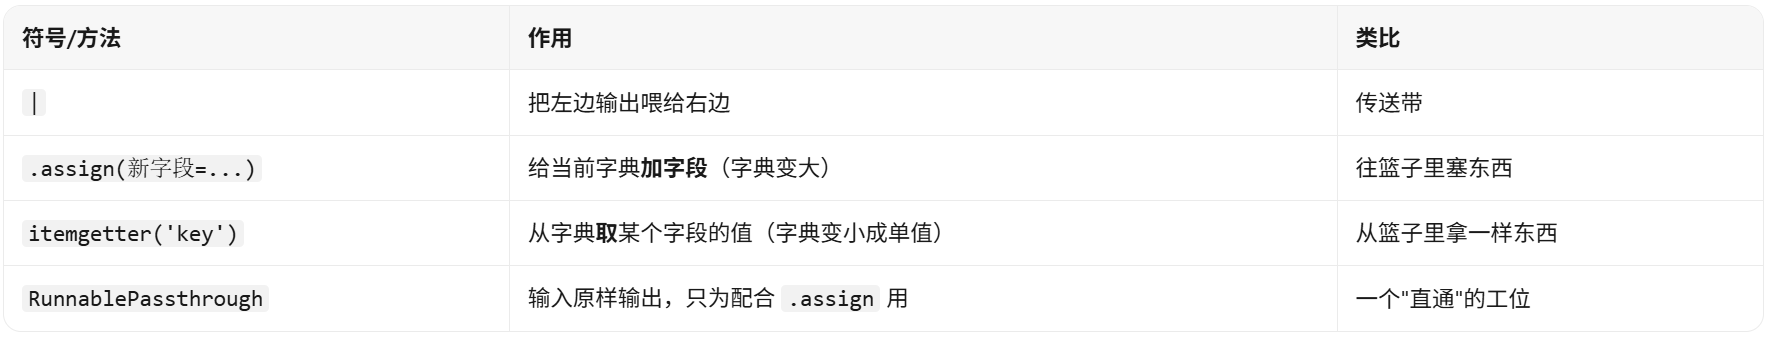